sudo apt install git-lfs for linux mint. Might need to download on other os aswell not shure

git lfs install
git lsf pull
wait for the images to download
unzip folders

run the following code
and then you are should have a folder "dataset_split" that has folders "train", "test", "val" that have folders 0,1,2,3,4,5

## Tavoite

Tässä notebookissa on tavoitteena kouluttaa konvoluutioneuroverkko ennustamaan käden kuvasta montako sormea on pystyssä.

## Data

Mallin käyttämä data koostuu kuvista missä on käsi ja tietty määrä sormia pystyssä 0, 1, 2, 3, 4 tai 5. Kuvat on jaettu kansioihin luokkansa perusteella ja seuraavan solun koodi jakaa nämä kuvat koulutus, validointi ja testi kansioihin (70%, 15%, 15%).

In [1]:
from pathlib import Path
import random
import shutil

SEED = 0
rng = random.Random(SEED)

source = Path("kuvat")
target = Path("dataset_split")

#removes target if it exist and makes it again so that when this code is rerun with a different seed there will be no problems
if target.exists():
    shutil.rmtree(target)

target.mkdir(parents=True, exist_ok=True)

for class_dir in sorted(source.iterdir()):
    if not class_dir.is_dir():
        continue

    images = sorted(
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    rng.shuffle(images)

    n = len(images)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    splits = {
        "train": images[:n_train],
        "val": images[n_train:n_train + n_val],
        "test": images[n_train + n_val:]
    }

    for split, files in splits.items():
        output_dir = target / split / class_dir.name
        output_dir.mkdir(parents=True, exist_ok=True)

        for file in files:
            shutil.copy2(file, output_dir / file.name)

        print(f"{class_dir.name} | {split}: {len(files)}")


.ipynb_checkpoints | train: 0
.ipynb_checkpoints | val: 0
.ipynb_checkpoints | test: 0
0 | train: 280
0 | val: 60
0 | test: 61
1 | train: 322
1 | val: 69
1 | test: 70
2 | train: 331
2 | val: 71
2 | test: 72
3 | train: 375
3 | val: 80
3 | test: 81
4 | train: 229
4 | val: 49
4 | test: 50
5 | train: 319
5 | val: 68
5 | test: 69


## Datan valmistelu 

Kuvat ladataan koulutus-, validointi- ja testausaineistoihin ja kuvat muunnetaan 128x128 pikselin kokoisiksi ja jaetaan 32 kuvan eriin.

Solun lopussa on augmentaatiofunktio, joka peilaa kuvia satunnaisesti vaakasuunnassa ja kiertää niitä satunnaisesti enintään noin 10 astetta.

In [2]:
import keras
from keras import layers
from keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    "dataset_split/train",
    image_size = (128, 128),
    batch_size = 32)
validation_dataset = image_dataset_from_directory(
    "dataset_split/val",
    image_size = (128, 128),
    batch_size = 32)
test_dataset = image_dataset_from_directory(
    "dataset_split/test",
    image_size = (128, 128),
    batch_size = 32,
    shuffle=False)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
])

I0000 00:00:1794334925.628941   74424 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794334925.683441   74424 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794334927.495996   74424 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Found 1856 files belonging to 6 classes.
Found 397 files belonging to 6 classes.
Found 403 files belonging to 6 classes.


E0000 00:00:1794334928.383250   74424 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## Mallintaminen

Mallin muodon näkee seuraavasta solusta. Epocheja on suuri määrä sillä oppiminen on niin hidasta. En saanut nopeutettua oppimista learnig ratea muuttamalla val accuracy pysyi vain paikoillaan tai pomppi. 

Halusin käyttää batch normalizationia regulaationa, mutta en saanut sitä toimimaan jostain syystä tässä mallissa.

In [3]:
inputs = keras.Input(shape=(128, 128, 3))

x = data_augmentation(inputs)

x = layers.Rescaling(1.0 / 255)(x)

x = layers.Conv2D(filters=32, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Dropout(0.2)(x)

x = layers.Conv2D(filters=64, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Dropout(0.2)(x)

x = layers.Conv2D(filters=128, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Dropout(0.2)(x)

x = layers.Conv2D(filters=256, kernel_size=3)(x)
#x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)


x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(6, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

#use_bias=False kun batch norm

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 389,958 (1.49 MB)

 Trainable params: 389,958 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
from tensorflow.keras.optimizers import Adam

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=Adam(learning_rate=0.001),
    metrics=["accuracy"],
)

history = model.fit(
    train_dataset,
    epochs=500,
    validation_data=validation_dataset,
)

Epoch 1/500


/home/user/projects/Neuroverkkoprojekti/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 ━━━━━━━━━━━━━━━━━━━━ 29s 472ms/step - accuracy: 0.1923 - loss: 1.7932 - val_accuracy: 0.2015 - val_loss: 1.7822
Epoch 2/500
58/58 ━━━━━━━━━━━━━━━━━━━━ 27s 463ms/step - accuracy: 0.2015 - loss: 1.7825 - val_accuracy: 0.2015 - val_loss: 1.7846
Epoch 3/500
58/58 ━━━━━━━━━━━━━━━━━━━━ 27s 465ms/step - accuracy: 0.1994 - loss: 1.7838 - val_accuracy: 0.2015 - val_loss: 1.7814
Epoch 4/500
58/58 ━━━━━━━━━━━━━━━━━━━━ 29s 495ms/step - accuracy: 0.1988 - loss: 1.7828 - val_accuracy: 0.2015 - val_loss: 1.7832
Epoch 5/500
58/58 ━━━━━━━━━━━━━━━━━━━━ 29s 494ms/step - accuracy: 0.2026 - loss: 1.7828 - val_accuracy: 0.2015 - val_loss: 1.7827
Epoch 6/500
58/58 ━━━━━━━━━━━━━━━━━━━━ 28s 472ms/step - accuracy: 0.2020 - loss: 1.7823 - val_accuracy: 0.2015 - val_loss: 1.7815
Epoch 7/500
58/58 ━━━━━━━━━━━━━━━━━━━━ 28s 470ms/step - accuracy: 0.2026 - loss: 1.7822 - val_accuracy: 0.2015 - val_loss: 1.7807
Epoch 8/500
58/58 ━━━━━━━━━━━━━━━━━━━━ 28s 481ms/step - accuracy: 0.2015 - loss: 1.7827 - val_accuracy

## Tulosten arviointi

Luulen että malli ylisovittaa ja saa hyvän validation accuracyn vain koska validointi ja harjoitusdata ovat keskenään niin samankaltaista. Testi datakin on hyvin samankaltaista harjoitusdatan kanssa ja siksi test accuracykin on korkea. Mallia olisi hyvä testata myös kokonaan uusilla kuvilla, joita ryhmämme ei ole ottanut. Toisaalta aihe on suhteellisen simppeli ja käsistä ei voisi ottaa kuvia kovinkaan monella eri tavalla.

Loss ja accyracy kuvaajista huomaa että malli ei muutu pariinkymmeneen ensimmäiseen epochiin jonka jälkeen tulee räjähdysmäinen kasvu ja sitten tasaantuminen. Kuvaajien perusteella 500 epochin kohdalla ei ole vielä saavutettu mallin varmaa parasta versiota.

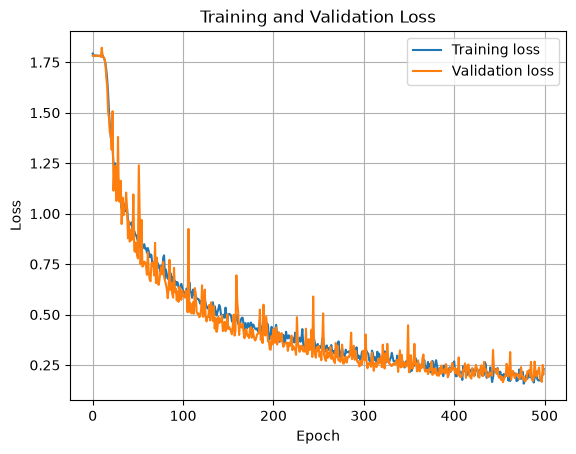

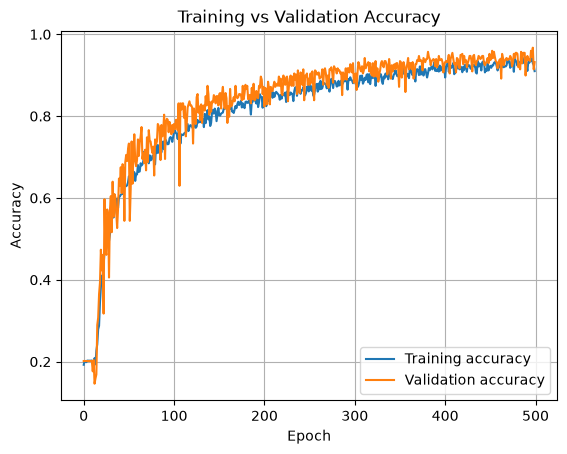

In [5]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()



13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 173ms/step - accuracy: 0.9057 - loss: 0.2208
Test Loss: 0.22082890570163727
Test Accuracy: 0.9057071805000305
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step


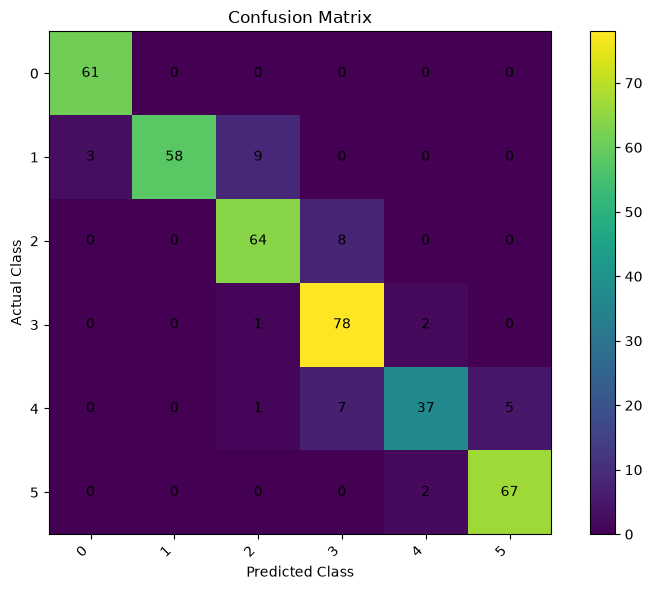

In [8]:
import numpy as np

test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

#model.save("v5.keras")

#AI cm:
# True labels
y_true = np.concatenate([y.numpy() for x, y in test_dataset])

# Predicted labels
y_pred = np.argmax(model.predict(test_dataset), axis=1)

# Create confusion matrix
cm = np.zeros((6, 6), dtype=int)

for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

# Plot
plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.colorbar()

class_names = test_dataset.class_names

plt.xticks(range(6), class_names, rotation=45, ha='right')
plt.yticks(range(6), class_names)

for i in range(6):
    for j in range(6):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

Number of wrong predictions: 38


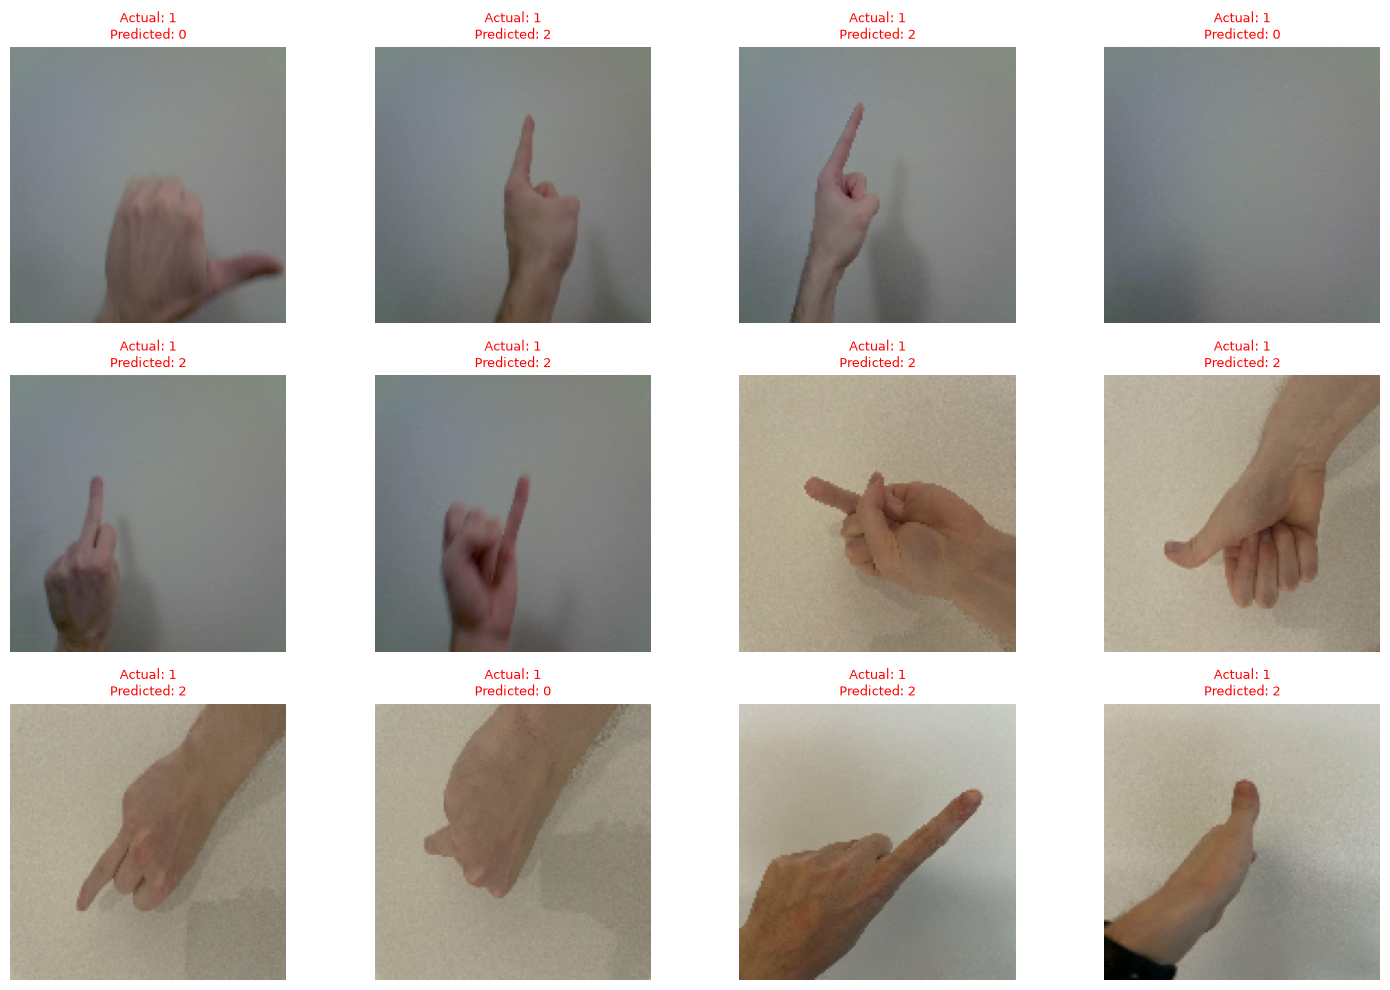

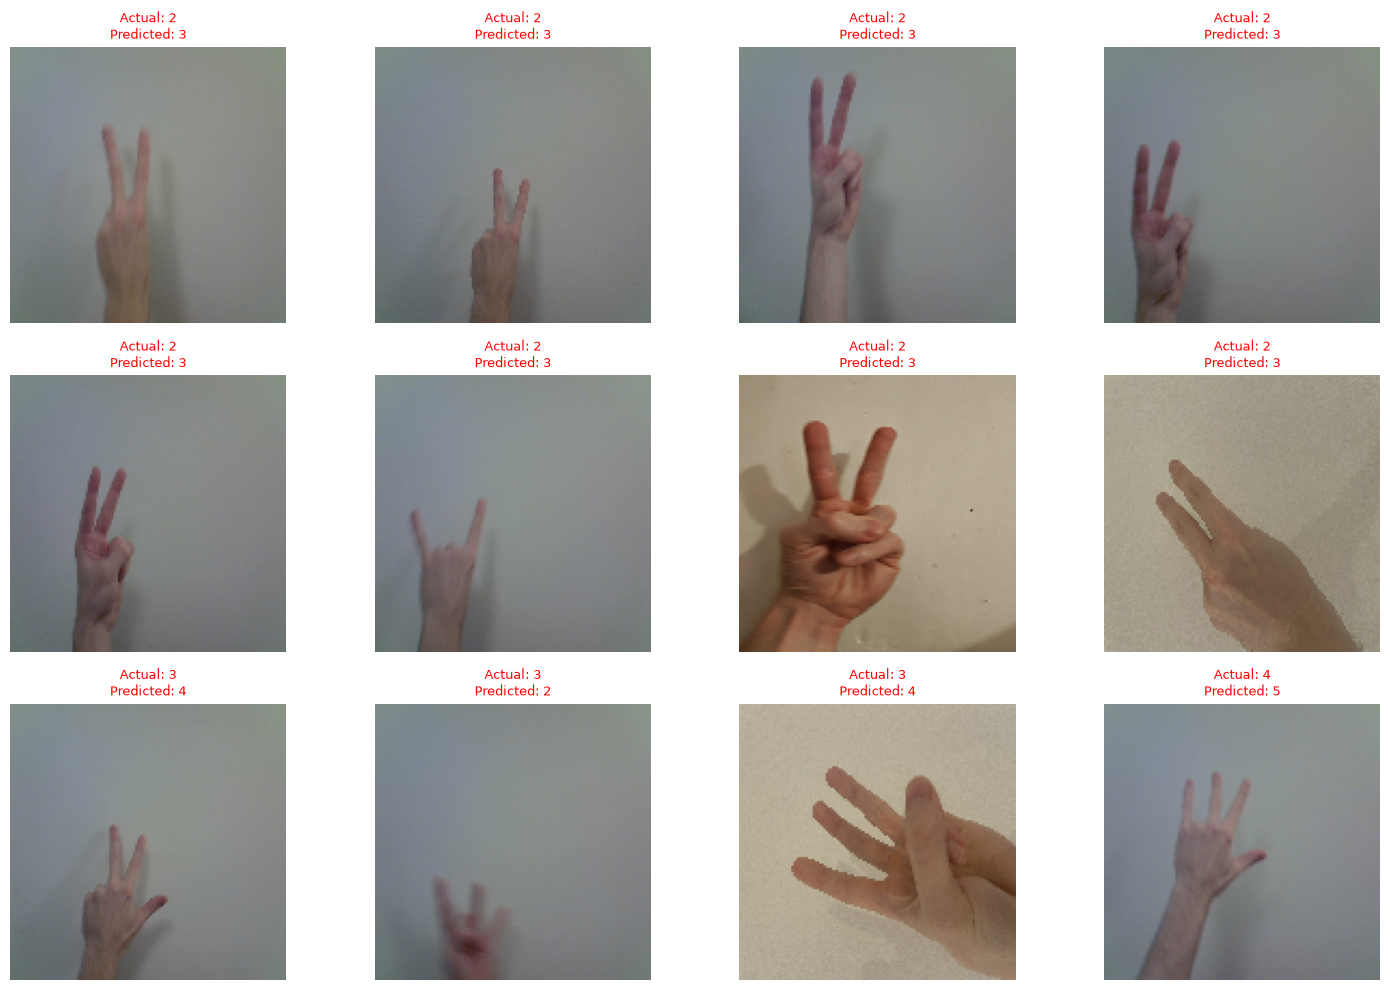

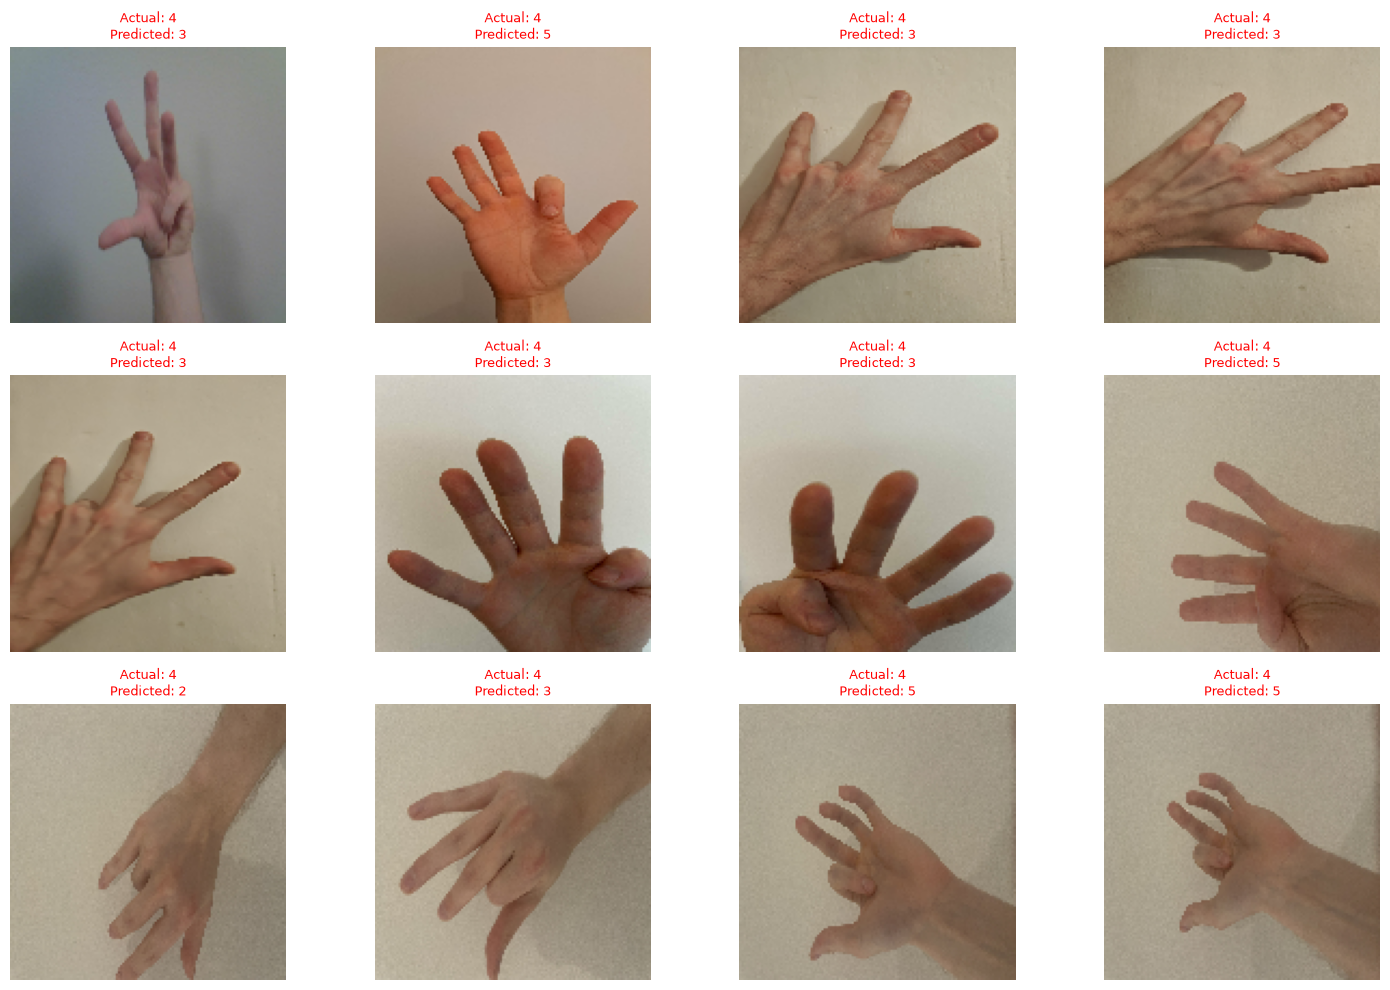

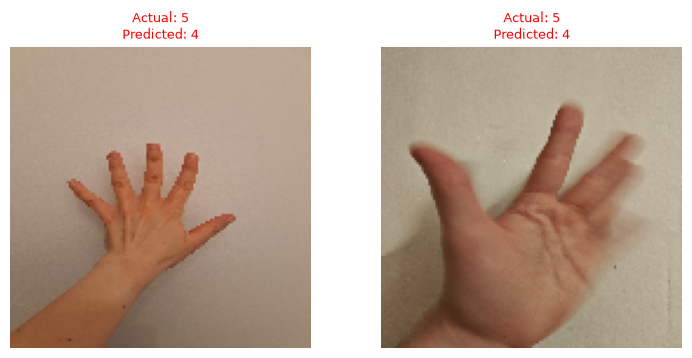

In [7]:
# Find wrongly classified images
wrong_indices = np.where(y_true != y_pred)[0]

print("Number of wrong predictions:", len(wrong_indices))

# Get all test images
X_test = np.concatenate([x.numpy() for x, y in test_dataset])

# Display wrong predictions
for start in range(0, len(wrong_indices), 12):

    batch_indices = wrong_indices[start:start + 12]

    plt.figure(figsize=(15, 10))

    for i, idx in enumerate(batch_indices):
        plt.subplot(3, 4, i + 1)

        plt.imshow(X_test[idx].astype("uint8"))

        plt.title(
            f"Actual: {class_names[y_true[idx]]}\n"
            f"Predicted: {class_names[y_pred[idx]]}",
            color='red',
            fontsize=9
        )

        plt.axis('off')

    plt.tight_layout()
    plt.show()

## Väärin luokitellut kuvat

Vääristä ennusteista oikean luokan alle on ennustettu 14 ja oikean luokan yli on ennustettu 24. 

Osa kuvista on selvästi huonoa dataa (kuvat on suomeita tai muuten huonoja). Kiinnotava huono data on tyhjä kuva joka on ennustettu 0 luokkaan vaikka oikeasti löytyy luokasta 1. Tämä voisi olla haluttu ominaisuus jota ei olla edes mietitty mallia luodessa. 

Väärin luokitelluista kuvista suuri osa on kämmenen puolelta tai sellaisia missä jonkin sormen ensimmäinen tyvi on pystyssä. Omana hypoteesina on että kämmenen puolisista kuvista malli luokittelee kämmenen edessä pidetyn peukalon joskus pystyssä olevaksi sormeksi ja joskus mallilla on vaikeuksia havaita onko ensimmäinen tyvi kokonainen pystyssä oleva sormi vai taitettu sormi.

Näyttäisi myös että osissa kuvista malli erehtyy seinällä olevan varjoa pystyssä olevaksi sormeksi.

Vaikeinta on selittä miksi joskus malli erehtyy tunnistamaan kuvan oikeaa luokkaa alempaan luokkaan. Yhdessä kuvassa on selvästi 5 sormea pystyssä eikä paljoa häiriötä ja malli luokittelee sen luokkan 4. Suurimmalle osalle näistä ali luokitteluista en keksi mitään ilmenevää syytä.